name- ujjawal chauhan labsheet-08


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

# Generate sample customer data
np.random.seed(42)
n = 500

df = pd.DataFrame({
    "Tenure": np.random.randint(1, 73, n),
    "MonthlyCharges": np.random.randint(20, 121, n),
    "Contract": np.random.choice(
        ["Month-to-month", "One year", "Two year"], n
    ),
    "InternetService": np.random.choice(
        ["DSL", "Fiber optic", "No"], n
    ),
    "SupportCalls": np.random.randint(0, 6, n)
})

# Generate churn labels
score = (
    (df["Contract"] == "Month-to-month").astype(int) * 2
    + (df["Tenure"] < 12).astype(int)
    + (df["MonthlyCharges"] > 80).astype(int)
    + (df["SupportCalls"] >= 3).astype(int)
)

df["Churn"] = np.where(score >= 3, "Yes", "No")

print(df.head())
print("\nDataset Shape:", df.shape)
print("\nMissing Values:\n", df.isnull().sum())

   Tenure  MonthlyCharges        Contract InternetService  SupportCalls Churn
0      52              89  Month-to-month             DSL             0   Yes
1      15              50        One year             DSL             2    No
2      72              38  Month-to-month             DSL             5   Yes
3      61              80  Month-to-month              No             4   Yes
4      21              73  Month-to-month     Fiber optic             4   Yes

Dataset Shape: (500, 6)

Missing Values:
 Tenure             0
MonthlyCharges     0
Contract           0
InternetService    0
SupportCalls       0
Churn              0
dtype: int64


In [2]:
# Separate input features and target
X = df.drop("Churn", axis=1)
y = df["Churn"]

# Identify numerical and categorical columns
numeric_features = ["Tenure", "MonthlyCharges", "SupportCalls"]
categorical_features = ["Contract", "InternetService"]

# Encode categorical data
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     categorical_features)
])

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Apply preprocessing
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Preprocessing completed successfully.")

Training samples: 400
Testing samples: 100
Preprocessing completed successfully.


In [3]:
# Create Decision Tree Classifier
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    random_state=42
)

# Train the model
model.fit(X_train_processed, y_train)

# Predict customer churn
y_pred = model.predict(X_test_processed)

print("Decision Tree Model Trained Successfully!")
print("Sample Predictions:", y_pred[:10])

Decision Tree Model Trained Successfully!
Sample Predictions: ['No' 'No' 'No' 'No' 'Yes' 'No' 'Yes' 'No' 'No' 'No']


Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-Score : 1.0


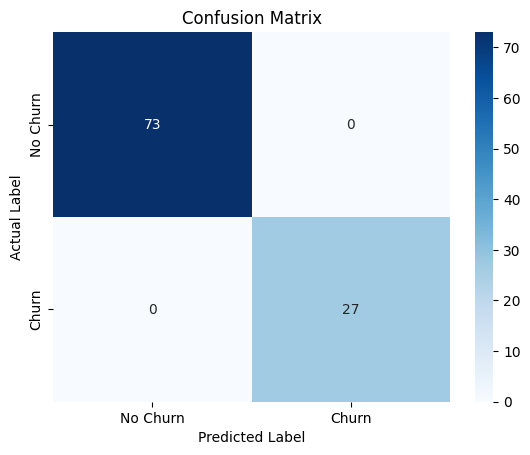


Classification Report:

              precision    recall  f1-score   support

          No       1.00      1.00      1.00        73
         Yes       1.00      1.00      1.00        27

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100



In [4]:
# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, pos_label="Yes", zero_division=0
)
recall = recall_score(
    y_test, y_pred, pos_label="Yes", zero_division=0
)
f1 = f1_score(
    y_test, y_pred, pos_label="Yes", zero_division=0
)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-Score :", round(f1, 4))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=["No", "Yes"])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

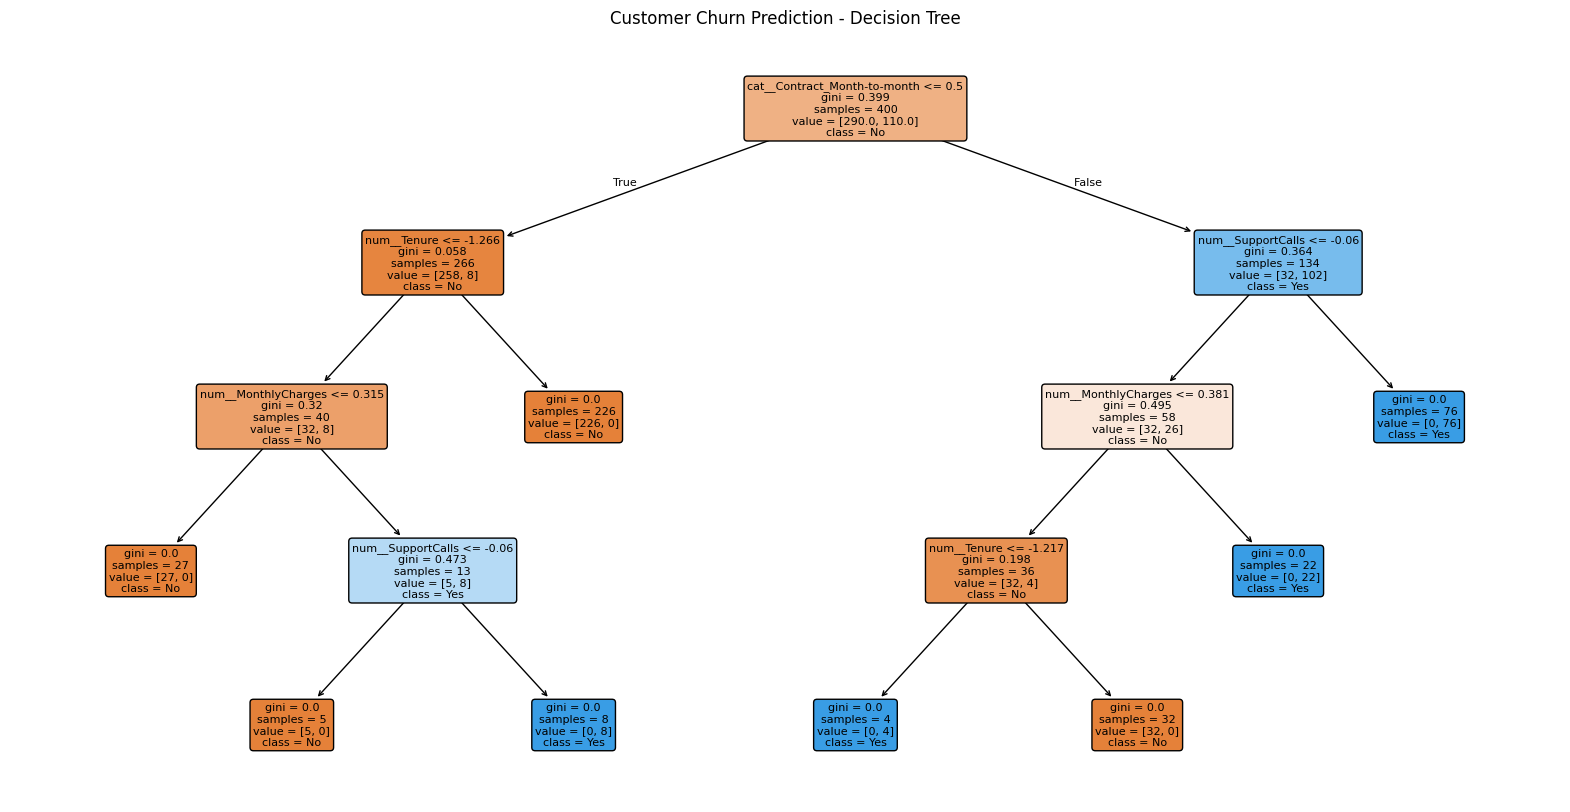

Feature Importance:

cat__Contract_Month-to-month        0.597271
num__MonthlyCharges                 0.176957
num__SupportCalls                   0.164142
num__Tenure                         0.061630
cat__Contract_One year              0.000000
cat__Contract_Two year              0.000000
cat__InternetService_DSL            0.000000
cat__InternetService_Fiber optic    0.000000
cat__InternetService_No             0.000000
dtype: float64


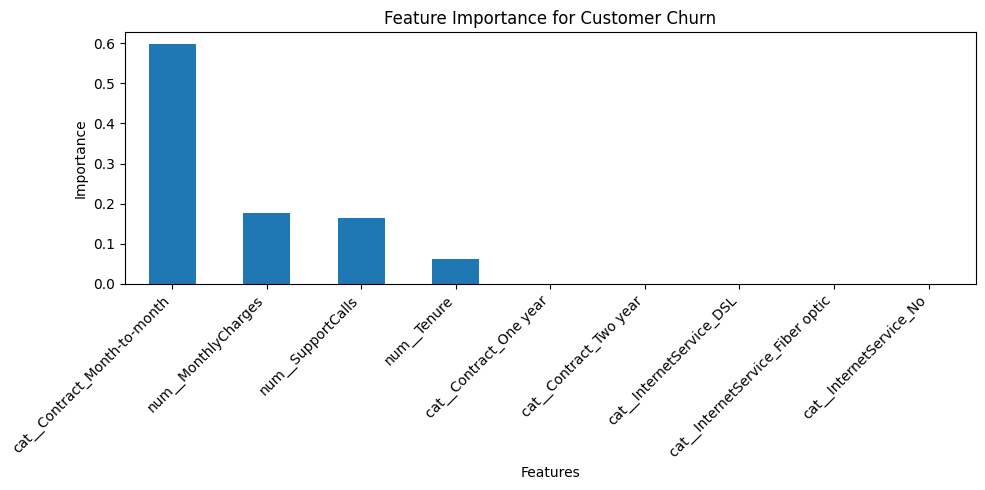

In [5]:
# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Visualize the Decision Tree
plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=feature_names,
    class_names=model.classes_,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Customer Churn Prediction - Decision Tree")
plt.show()

# Display feature importance
importance = pd.Series(
    model.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

print("Feature Importance:\n")
print(importance)

importance.plot(kind="bar", figsize=(10, 5))
plt.title("Feature Importance for Customer Churn")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()